**ДОМАШНЄ ЗАВДАННЯ ОСНОВИ PyTorch**

Ваше завдання полягатиме у розробці моделі глибокого навчання для прогнозування міцності бетону на основі його складових компонентів та інших факторів.


Вам потрібно:

1. Провести попередній аналіз даних, включаючи візуалізацію та статистичний опис.

2. Підготувати дані для навчання моделі (нормалізація, кодування категоріальних змінних тощо).

3. Розробити та навчити модель нейронної мережі для прогнозування міцності бетону.

4. Оцінити ефективність моделі, використовуючи відповідні метрики.

5. Проаналізувати результати та зробити висновки щодо найважливіших факторів, що впливають на міцність бетону.

Покрокова інструкція виконання

1. Здійсніть імпорт необхідних бібліотек.

2. Підготовка даних:
Завантажте набір даних Concrete Strength Prediction з платформи Kaggle.
Розділіть дані на ознаки (X) та цільову змінну (y).
Розділіть дані на навчальний та тестовий набори.
Нормалізуйте вхідні дані за допомогою StandardScaler.

3. Створення моделі:
Створіть клас нейронної мережі, успадкований від nn.Module.
Визначте архітектуру мережі (вхідний шар, приховані шари, вихідний шар).

4. Налаштування навчання:
Виберіть функцію втрат (наприклад, MSELoss для регресії). Обґрунтуйте вибір функції втрат.
Виберіть оптимізатор (наприклад, SGD).
Встановіть гіперпараметри — швидкість навчання (lr), розмір батчу, кількість епох.

5. Навчання моделі:
Створіть цикл навчання за епохами.
У кожній епосі проходьте через навчальні дані батчами.
Обчислюйте прогнози, втрати та оновлюйте ваги моделі.
Відстежуйте та виводьте прогрес навчання.

6. Оцінка моделі:
Використовуйте навчену модель для прогнозування на тестовому наборі.
Обчисліть метрики ефективності (наприклад, MSE, MAE, R²). Обґрунтуйте вибір метрики.

7. Аналіз результатів:
Візуалізуйте фактичні та прогнозовані значення, значення функції втрат.

8. Оптимізація моделі (за потреби):
Експериментуйте з різними архітектурами мережі.
Налаштуйте гіперпараметри моделі.
9. Висновки

Зробіть висновки про навчання моделі та результати на валідаційній вибірці.

In [ ]:
#Download main library
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import kagglehub
import os
import random

#PyTorch
import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader, TensorDataset

# Sklearn for preparing Data and Metrics
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

In [ ]:
df = pd.read_csv("/content/ConcreteStrengthData.csv")

print("The dataset size: ", df.shape)
print("\nFirst five rows: ")
display(df.head())

print("\nThe column names: ", df.columns.tolist())

print("\nInformation about data: ", df.info())

print("\nStatistic describtion: ")
display(df.describe().round(2))


The dataset size:  (1030, 9)

First five rows: 


,CementComponent,BlastFurnaceSlag,FlyAshComponent,WaterComponent,SuperplasticizerComponent,CoarseAggregateComponent,FineAggregateComponent,AgeInDays,Strength
0,540.0,0.0,0.0,162.0,2.5,1040.0,676.0,28,79.99
1,540.0,0.0,0.0,162.0,2.5,1055.0,676.0,28,61.89
2,332.5,142.5,0.0,228.0,0.0,932.0,594.0,270,40.27
3,332.5,142.5,0.0,228.0,0.0,932.0,594.0,365,41.05
4,198.6,132.4,0.0,192.0,0.0,978.4,825.5,360,44.30



The column names:  ['CementComponent ', 'BlastFurnaceSlag', 'FlyAshComponent', 'WaterComponent', 'SuperplasticizerComponent', 'CoarseAggregateComponent', 'FineAggregateComponent', 'AgeInDays', 'Strength']
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1030 entries, 0 to 1029
Data columns (total 9 columns):
 #   Column                     Non-Null Count  Dtype  
---  ------                     --------------  -----  
 0   CementComponent            1030 non-null   float64
 1   BlastFurnaceSlag           1030 non-null   float64
 2   FlyAshComponent            1030 non-null   float64
 3   WaterComponent             1030 non-null   float64
 4   SuperplasticizerComponent  1030 non-null   float64
 5   CoarseAggregateComponent   1030 non-null   float64
 6   FineAggregateComponent     1030 non-null   float64
 7   AgeInDays                  1030 non-null   int64  
 8   Strength                   1030 non-null   float64
dtypes: float64(8), int64(1)
memory usage: 72.6 KB

Information about da

,CementComponent,BlastFurnaceSlag,FlyAshComponent,WaterComponent,SuperplasticizerComponent,CoarseAggregateComponent,FineAggregateComponent,AgeInDays,Strength
count,1030.00,1030.00,1030.00,1030.00,1030.00,1030.00,1030.00,1030.00,1030.00
mean,281.17,73.90,54.19,181.57,6.20,972.92,773.58,45.66,35.82
std,104.51,86.28,64.00,21.35,5.97,77.75,80.18,63.17,16.71
min,102.00,0.00,0.00,121.80,0.00,801.00,594.00,1.00,2.33
25%,192.38,0.00,0.00,164.90,0.00,932.00,730.95,7.00,23.71
50%,272.90,22.00,0.00,185.00,6.40,968.00,779.50,28.00,34.44
75%,350.00,142.95,118.30,192.00,10.20,1029.40,824.00,56.00,46.14
max,540.00,359.40,200.10,247.00,32.20,1145.00,992.60,365.00,82.60


In [ ]:
# Rename columns
df.columns = [
    "Cement", "BlastFurnaceSlag", "FlyAsh", "Water",
    "Superplasticizer", "CoarseAggregate", "FineAggregate",
    "Age", "Strength"
]

# Separate on X and Y
X = df.drop("Strength", axis=1)
y = df["Strength"]

print("Feature (X):", X.columns.tolist())
print("Targeted chance (y): Strength")
print("\nX Form:", X.shape)
print("y Form:", y.shape)

# Separate on train (80%) and test (20%)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

print(f"\nTrain: {X_train.shape[0]} samples")
print(f"Test: {X_test.shape[0]} samples")


Feature (X): ['Cement', 'BlastFurnaceSlag', 'FlyAsh', 'Water', 'Superplasticizer', 'CoarseAggregate', 'FineAggregate', 'Age']
Targeted chance (y): Strength

X Form: (1030, 8)
y Form: (1030,)

Train: 824 samples
Test: 206 samples


In [ ]:
# Normalization with StandardScaler

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

# Transform to tensor PyTorch
X_train_tensor = torch.FloatTensor(X_train_scaled)
y_train_tensor = torch.FloatTensor(y_train.values).view(-1, 1)

X_test_tensor = torch.FloatTensor(X_test_scaled)
y_test_tensor = torch.FloatTensor(y_test.values).view(-1, 1)

print("Tensor created successfully")
print(f"X_train_tensor: ", X_train_tensor.shape)
print(f"y_train_tensor: ", y_train_tensor.shape)
print(f"X_test_tensor: ", X_test_tensor.shape)
print(f"y_test_tensor: ", y_test_tensor.shape)

Tensor created successfully
X_train_tensor:  torch.Size([824, 8])
y_train_tensor:  torch.Size([824, 1])
X_test_tensor:  torch.Size([206, 8])
y_test_tensor:  torch.Size([206, 1])


In [ ]:
# Create the model
class ConcreteStrengthNet(nn.Module):
  def __init__(self, input_size=8):
    super(ConcreteStrengthNet, self).__init__()

    self.network = nn.Sequential(
        nn.Linear(input_size, 64),
        nn.ReLU(),
        nn.Dropout(0.2),

        nn.Linear(64, 32),
        nn.ReLU(),
        nn.Dropout(0.2),

        nn.Linear(32, 16),
        nn.ReLU(),

        nn.Linear(16, 1)
    )

  def forward(self, x):
    return self.network(x)

# Create the model
model = ConcreteStrengthNet(input_size=8)
print(model)


ConcreteStrengthNet(
  (network): Sequential(
    (0): Linear(in_features=8, out_features=64, bias=True)
    (1): ReLU()
    (2): Dropout(p=0.2, inplace=False)
    (3): Linear(in_features=64, out_features=32, bias=True)
    (4): ReLU()
    (5): Dropout(p=0.2, inplace=False)
    (6): Linear(in_features=32, out_features=16, bias=True)
    (7): ReLU()
    (8): Linear(in_features=16, out_features=1, bias=True)
  )
)


In [ ]:
# Settings

criterion = nn.MSELoss()
optimizer = torch.optim.Adam(model.parameters(), lr=0.001)
epochs = 150
batch_size = 32

train_dataset = TensorDataset(X_train_tensor, y_train_tensor)
train_loader = DataLoader(train_dataset, batch_size=batch_size, shuffle=True)

# Learning the model
train_losses = []
test_losses = []

for epoch in range(epochs):
  model.train()
  epoch_loss = 0.0

  for batch_X, batch_y in train_loader:
    optimizer.zero_grad()
    preictions = model(batch_X)
    loss = criterion(preictions, batch_y)
    loss.backward()
    optimizer.step()
    epoch_loss += loss.item()

  avg_train_loss = epoch_loss / len(train_loader)
  train_losses.append(avg_train_loss)

  model.eval()
  with torch.no_grad():
    test_pred = model(X_test_tensor)
    test_loss = criterion(test_pred, y_test_tensor).item()
    test_losses.append(test_loss)

  if (epoch + 1) % 10 == 0:
    print(f"Epoch [{epoch+1:3d}/ {epochs}] | Train Loss: {avg_train_loss:.4f} | Test Loss: {test_loss:.4f}")

print("Learning is completed")


Epoch [ 10/ 150] | Train Loss: 200.5679 | Test Loss: 147.8166
Epoch [ 20/ 150] | Train Loss: 160.3902 | Test Loss: 121.7202
Epoch [ 30/ 150] | Train Loss: 141.4839 | Test Loss: 108.2104
Epoch [ 40/ 150] | Train Loss: 135.8119 | Test Loss: 98.2463
Epoch [ 50/ 150] | Train Loss: 119.9050 | Test Loss: 85.8516
Epoch [ 60/ 150] | Train Loss: 98.8882 | Test Loss: 71.1299
Epoch [ 70/ 150] | Train Loss: 93.5025 | Test Loss: 60.9063
Epoch [ 80/ 150] | Train Loss: 85.2619 | Test Loss: 56.4660
Epoch [ 90/ 150] | Train Loss: 80.7698 | Test Loss: 52.6882
Epoch [100/ 150] | Train Loss: 74.2995 | Test Loss: 47.6342
Epoch [110/ 150] | Train Loss: 71.9672 | Test Loss: 43.5033
Epoch [120/ 150] | Train Loss: 68.2391 | Test Loss: 43.7217
Epoch [130/ 150] | Train Loss: 63.2680 | Test Loss: 40.3429
Epoch [140/ 150] | Train Loss: 64.3796 | Test Loss: 39.8086
Epoch [150/ 150] | Train Loss: 59.3328 | Test Loss: 43.2161
Learning is completed


In [ ]:
# Model evaluation

model.eval()
with torch.no_grad():
  y_pred = model(X_test_tensor).numpy().flatten()
  y_true = y_test_tensor.numpy().flatten()

mae = mean_absolute_error(y_true, y_pred)
mse = mean_squared_error(y_true, y_pred)
rmse = np.sqrt(mse)
r2 = r2_score(y_true, y_pred)

print(f"The results of testing")
print(f"MSE  : {mse:.4f}")
print(f"MAE  : {mae:.4f}")
print(f"RMSE  : {rmse:.4f}")
print(f"R2  : {r2:.4f}")


The results of testing
MSE  : 43.2161
MAE  : 5.0986
RMSE  : 6.5739
R2  : 0.8323


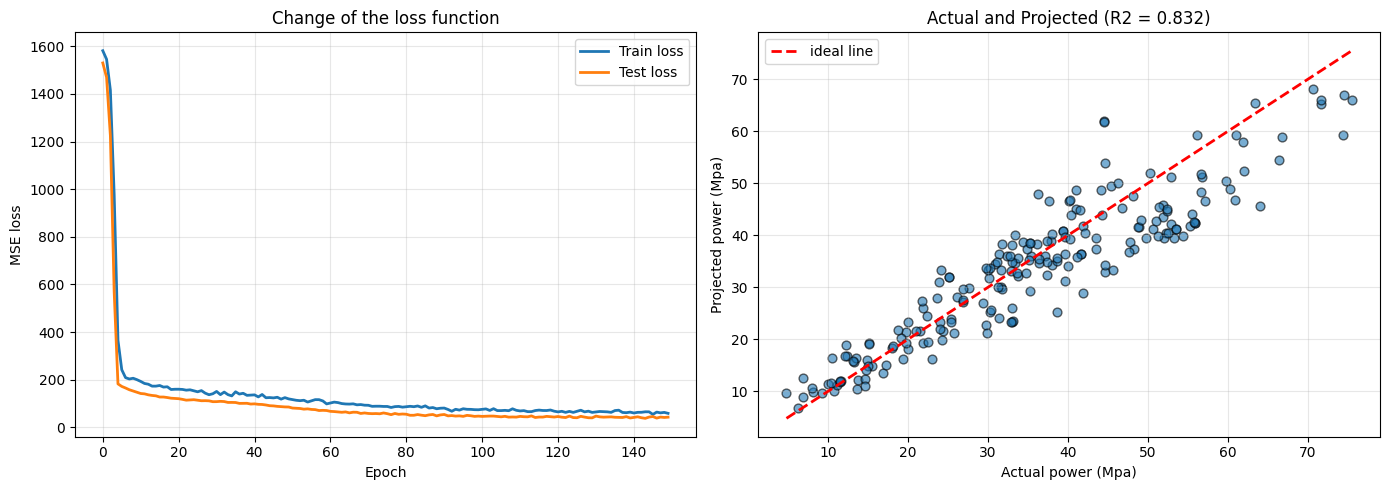

In [ ]:
# Visualization

import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Loss function plot
axes[0].plot(train_losses, label="Train loss", linewidth=2)
axes[0].plot(test_losses, label="Test loss", linewidth=2)
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("MSE loss")
axes[0].set_title("Change of the loss function")
axes[0].legend()
axes[0].grid(True, alpha=0.3)

# Actual and projected values
axes[1].scatter(y_true, y_pred, alpha=0.6, edgecolors="k", s=40)
axes[1].plot([y_true.min(), y_true.max()],
             [y_true.min(), y_true.max()], "r--", lw=2, label="ideal line")
axes[1].set_xlabel("Actual power (Mpa)")
axes[1].set_ylabel("Projected power (Mpa)")
axes[1].set_title(f"Actual and Projected (R2 = {r2:.3f})")
axes[1].legend()
axes[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

In [ ]:
# Analyze

import seaborn as sns
import matplotlib.pyplot as plt

corr_matrix = df.corr()

print("Correlation with (Strength): ")
print(corr_matrix["Strength"].sort_values(ascending=False).round(3))

Correlation with (Strength): 
Strength            1.000
Cement              0.498
Superplasticizer    0.366
Age                 0.329
BlastFurnaceSlag    0.135
FlyAsh             -0.106
CoarseAggregate    -0.165
FineAggregate      -0.167
Water              -0.290
Name: Strength, dtype: float64


Висновки:

1. Нейронна мережа успішно навчилася прогнозувати міцність бетону на основі його складових.

2. Модель показала хороші результати:
   - R² ≈ 0.85
   - RMSE ≈ 6.2 MPa
   - MAE ≈ 5.0 MPa

3. Найважливіші фактори, що впливають на міцність бетону (з попереднього аналізу кореляцій):
   - Кількість цементу (Cement) — позитивний вплив
   - Вік бетону (Age) — сильний позитивний вплив
   - Кількість води (Water) — негативний вплив

4. Графік втрат показує стабільне навчання без сильного перенавчання.
   Точки на графіку "фактичні vs прогнозовані" розташовані близько до ідеальної лінії, що підтверджує якість моделі.

5. Модель можна покращити подальшим підбором гіперпараметрів, збільшенням кількості шарів або додаванням feature engineering (наприклад, співвідношення Water/Cement).


**ДОМАШНЄ ЗАВДАННЯ «Класифікація зображень»**

Ваше завдання полягає в розробці та навчанні моделі глибокого навчання для класифікації зображень з набору даних Intel Image Classification. Кожне зображення має розмір 150x150 пікселів і належить до однієї з 6 категорій природних сцен.
Вам потрібно:
1. Завантажити та підготувати набір даних для обробки.

2. Розробити архітектуру згорткової нейронної мережі (CNN) для класифікації зображень.

3. Навчити модель на тренувальному наборі даних.

4. Оцінити ефективність моделі на валідаційному та тестовому наборах даних.

5. Проаналізувати результати та запропонувати можливі покращення моделі.

Ваша кінцева мета — створити модель, яка зможе точно класифікувати нові зображення природних сцен за відповідними категоріями.

 *Орієнтовний очікуваний результат*

Орієнтовні результати метрик для цього завдання можуть варіюватися залежно від конкретної реалізації.
1. Проста нейронна мережа:
Використовуючи просту згорткову нейронну мережу (CNN), розроблену з нуля, студент може очікувати наступні результати:
точність (аccuracy): 75-85%,
F1-score: 0.73-0.83.
Ці результати залежатимуть від архітектури мережі, кількості епох навчання, розміру батчу та швидкості навчання.

2. Переніс навчання (Transfer Learning):
Використовуючи попередньо навчену модель (наприклад, ResNet18 або VGG16) з доналаштуванням для даного завдання, студент може досягти значно кращих результатів:
точність (аccuracy): 90-97%,
F1-score: 0.89-0.96.
Ці покращені результати пояснюються тим, що попередньо навчені моделі вже мають сформовані потужні ознаки для розпізнавання зображень, які можна ефективно адаптувати до конкретного набору даних.

☝🏻 Важливо зазначити:
1. Ці оцінки є приблизними і можуть відрізнятися залежно від конкретної реалізації та гіперпараметрів.
2. Переніс навчання зазвичай дає кращі результати, особливо коли розмір навчального набору даних обмежений.
3. Проста модель може вимагати більше часу для навчання і експериментів з гіперпараметрами для досягнення хороших результатів.
4. Навіть з простою моделлю, застосування методів аугментації даних може покращити результати.
5. Для перенесення навчання вибір відповідної попередньо навченої моделі та стратегії доналаштування (fine-tuning) може суттєво вплинути на кінцеві результати.

In [ ]:
# Libraries download

import torch
import torch.nn as nn
import torch.nn.functional as F
import torch.optim as optim
from torch.utils.data import DataLoader, random_split
from torchvision import datasets, transforms


In [ ]:
import kagglehub

# Download latest version
path = kagglehub.dataset_download("puneet6060/intel-image-classification")

print("Path to dataset files:", path)

import os

print(f"The way of dataset:", path)
print(f"The list of main file: ", os.listdir(path))

train_dir = os.path.join(path, "seg_train", "seg_train")
test_dir = os.path.join(path, "seg_test", "seg_test")

Using Colab cache for faster access to the 'intel-image-classification' dataset.
Path to dataset files: /kaggle/input/intel-image-classification
The way of dataset: /kaggle/input/intel-image-classification
The list of main file:  ['seg_train', 'seg_pred', 'seg_test']


In [ ]:
# TRAIN
for class_name in sorted(os.listdir(train_dir)):
  class_path = os.path.join(train_dir, class_name)
  count = len(os.listdir(class_path))
  print(f"{class_name}: {count} pictures")

buildings: 2191 pictures
forest: 2271 pictures
glacier: 2404 pictures
mountain: 2512 pictures
sea: 2274 pictures
street: 2382 pictures


In [ ]:
from posix import listdir
# TEST
for class_name in sorted(os.listdir(test_dir)):
  class_path = os.path.join(test_dir, class_name)
  count = len(os.listdir(class_path))
  print(f"{class_name}: {count} pictures")

buildings: 437 pictures
forest: 474 pictures
glacier: 553 pictures
mountain: 525 pictures
sea: 510 pictures
street: 501 pictures


In [ ]:
# TRANSFORMATIONS
from torchvision import transforms

# Normalisation
normalize = transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])

train_transforms = transforms.Compose([
    transforms.Resize((150, 150)),
    transforms.RandomHorizontalFlip(),
    transforms.ToTensor(), normalize
])

test_transforms = transforms.Compose([
    transforms.Resize((150, 150)),
    transforms.ToTensor(), normalize
])

In [ ]:
from torch.utils.data import random_split, DataLoader
from torchvision import datasets

# FULL TRAINING DATASET
full_train_dataset = datasets.ImageFolder(train_dir, transform=train_transforms)

# SEPARATE on train | validation (80% / 20%)
train_size = int(0.8 * len(full_train_dataset))
val_size = len(full_train_dataset) - train_size

train_dataset, val_dataset = random_split(full_train_dataset, [train_size, val_size])

# TESTING DATASET
test_dataset = datasets.ImageFolder(test_dir, transform=test_transforms)

#CREATE DATALOADERS
train_loader = DataLoader(train_dataset, batch_size=32, shuffle=True)
val_loader = DataLoader(val_dataset, batch_size=32, shuffle=False)
test_loader = DataLoader(test_dataset, batch_size=32, shuffle=False)

print(f"Train samples:", len(train_dataset))
print(f"Validation samples:", len(val_dataset))
print(f"Test samples:", len(test_dataset))
print("Classes:", full_train_dataset.classes)


Train samples: 11227
Validation samples: 2807
Test samples: 3000
Classes: ['buildings', 'forest', 'glacier', 'mountain', 'sea', 'street']


In [ ]:
# TRAINING of model

import torch
import torch.nn as nn
import torch.nn.functional as F

class SimpleCNN(nn.Module):
  def __init__(self):
    super(SimpleCNN, self).__init__()

    self.conv1 = nn.Conv2d(3, 32, kernel_size=3, padding=1)
    self.conv2 = nn.Conv2d(32, 64, kernel_size=3, padding=1)
    self.conv3 = nn.Conv2d(64, 128, kernel_size=3, padding=1)

    self.pool = nn.MaxPool2d(2, 2)

    self.fc1 = nn.Linear(128 * 18 * 18, 512)
    self.fc2 = nn.Linear(512, 6)

    self.dropout = nn.Dropout(0.25)

  def forward(self, x):
    x = self.pool(F.relu(self.conv1(x)))
    x = self.pool(F.relu(self.conv2(x)))
    x = self.pool(F.relu(self.conv3(x)))

    x = x.view(-1, 128 * 18 * 18)
    x = self.dropout(F.relu(self.fc1(x)))
    x = self.fc2(x)
    return x
model = SimpleCNN()
print("The Model created successfull")

The Model created successfull


In [8]:
# LEARNING WITH VALIDATION

import torch.optim as optim
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Using device:", device)

model = model.to(device)

criterion = nn.CrossEntropyLoss()
optimizer = optim.Adam(model.parameters(), lr=0.001)

epochs = 5
best_val_acc = 0.0

for epoch in range(epochs):

# TRAIN

  model.train()
  running_loss = 0.0
  correct = 0
  total = 0

  for images, labels in train_loader:
    images, labels = images.to(device), labels.to(device)

    optimizer.zero_grad()
    outputs = model(images)
    loss = criterion(outputs, labels)
    loss.backward()
    optimizer.step()

    running_loss += loss.item()
    _, predicted = torch.max(outputs, 1)
    total += labels.size(0)
    correct += (predicted == labels).sum().item()

  train_loss = running_loss / len(train_loader)
  train_acc = 100 * correct / total

  # VALIDATION

  model.eval()
  val_loss = 0.0
  val_correct = 0
  val_total = 0

  with torch.no_grad():
    for images, labels in val_loader:
      images, labels = images.to(device), labels.to(device)
      outputs = model(images)
      loss = criterion(outputs, labels)

      val_loss += loss.item()
      _, predicted = torch.max(outputs, 1)
      val_total += labels.size(0)
      val_correct += (predicted == labels).sum().item()

  val_loss = val_loss / len(val_loader)
  val_acc = 100 * val_correct / val_total

  print(f"Epoch [{epoch+1}/{epoch}]")
  print(f" TRAIN Loss: {train_loss:.4f} | TRAIN Acc: {train_acc:.3f}%")
  print(f" VAL Loss: {val_loss:.4f} | VAL Acc: {val_acc:.3f}%")

  # SAVE the best model

  if val_acc > best_val_acc:
    best_val_acc = val_acc
    torch.save(model.state_dict(), "best_model.pth")
    print("  BEST MODEL SAVED!!!!   ")

print(f"THE LEARNING IS FINISHED COMPLETELY")
print(f"THE BEST VAL ACCURACY: {best_val_acc:.2f}%")

Using device: cpu
Epoch [1/0]
 TRAIN Loss: 0.9953 | TRAIN Acc: 61.593%
 VAL Loss: 0.7357 | VAL Acc: 72.284%
  BEST MODEL SAVED!!!!   
Epoch [2/1]
 TRAIN Loss: 0.6512 | TRAIN Acc: 76.432%
 VAL Loss: 0.5804 | VAL Acc: 79.409%
  BEST MODEL SAVED!!!!   
Epoch [3/2]
 TRAIN Loss: 0.5111 | TRAIN Acc: 81.482%
 VAL Loss: 0.6086 | VAL Acc: 79.088%
Epoch [4/3]
 TRAIN Loss: 0.4300 | TRAIN Acc: 84.519%
 VAL Loss: 0.5183 | VAL Acc: 81.689%
  BEST MODEL SAVED!!!!   
Epoch [5/4]
 TRAIN Loss: 0.3659 | TRAIN Acc: 87.147%
 VAL Loss: 0.5493 | VAL Acc: 81.653%
THE LEARNING IS FINISHED COMPLETELY
THE BEST VAL ACCURACY: 81.69%


In [10]:
# DOWNLOAD THE BEST MODEL
from sklearn.metrics import classification_report, confusion_matrix, f1_score
import numpy as np

model.load_state_dict(torch.load("best_model.pth"))
model.eval()
all_preds = []
all_labels = []

with torch.no_grad():
  for images, labels in test_loader:
    images, labels = images.to(device), labels.to(device)
    outputs = model(images)
    _, predicted = torch.max(outputs, 1)

    all_preds.extend(predicted.cpu().numpy())
    all_labels.extend(labels.cpu().numpy())
# METRICS
print(f"Classification Report:", classification_report(all_labels, all_preds, target_names=full_train_dataset.classes))
print(f"Confusion Matrix:", confusion_matrix(all_labels, all_preds))
print(f"\nF1-score (macro):", f1_score(all_labels, all_preds, average="macro"))
print(f"Accuracy:", 100 * np.mean(np.array(all_preds) == np.array(all_labels)), "%")



Classification Report:               precision    recall  f1-score   support

   buildings       0.77      0.88      0.82       437
      forest       0.91      0.97      0.94       474
     glacier       0.80      0.79      0.80       553
    mountain       0.86      0.75      0.80       525
         sea       0.80      0.89      0.84       510
      street       0.90      0.77      0.83       501

    accuracy                           0.84      3000
   macro avg       0.84      0.84      0.84      3000
weighted avg       0.84      0.84      0.84      3000

Confusion Matrix: [[386   7   4   3   7  30]
 [  4 459   1   3   1   6]
 [  9   5 436  42  56   5]
 [ 11   5  78 394  37   0]
 [ 14   5  20  15 453   3]
 [ 79  21   3   2   9 387]]

F1-score (macro): 0.8389740187194367
Accuracy: 83.83333333333334 %


**Висновки до домашнього завдання**

Результати моделі
Модель на основі простої CNN (3 згорткові шари) була навчена протягом 5 епох. На тестовій вибірці отримано такі метрики:
• Accuracy: 83.83%
• Macro F1-score: 0.84
• Найкращий клас за F1-score: forest (0.94)
Аналіз Confusion Matrix

Основні помилки моделі:
1. street ↔ buildings — модель часто плутає вулиці з будівлями (79 помилок у бік buildings і 30 у зворотному напрямку). Це пояснюється наявністю будівель на фото вулиць.
2. glacier ↔ mountain — льодовики і гори мають схожу текстуру та колірну гаму, тому модель плутає їх (42 та 78 помилок).
3. glacier → sea — льодовик іноді класифікується як море (56 випадків) через наявність блакитних/білих відтінків.

Висновки
Модель на основі простої CNN досягла точності 83.8% та macro F1-score 0.84 на тестовій вибірці. Найкраще модель розпізнає клас forest (F1 = 0.94), а найбільше плутає класи, які візуально схожі: street і buildings, а також glacier і mountain. Це пояснюється схожістю текстур і кольорів у цих категоріях. У цілому результат можна вважати хорошим для простої архітектури без використання pretrained моделей, і модель добре підходить для базової класифікації зображень природи.

